# BB84 Quantum Key Distribution with Qiskit - step-by-step walkthrough

*Honours research artefact - "An Exploratory Analysis of Quantum Computing Programming Using Qiskit" (T. Diraditsile, CPUT, 2026).*

This notebook walks through every layer of the hybrid quantum-classical QKD application (proposal Figure 6):

1. Qubit encoding in two bases (superposition)
2. Measurement collapse and why the *wrong* basis gives a random bit
3. The full BB84 circuit, executed on the Qiskit Aer simulator
4. Eve's intercept-resend attack and the 25 % QBER signature
5. Classical post-processing - sifting, QBER estimation, Cascade, privacy amplification
6. Using the key: encrypted chat between Alice and Bob

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Encoding a bit in two bases

| Bit | Z basis (+) | X basis (×) |
|---|---|---|
| 0 | \|0⟩ | \|+⟩ = (\|0⟩+\|1⟩)/√2 |
| 1 | \|1⟩ | \|−⟩ = (\|0⟩−\|1⟩)/√2 |

In Qiskit the X-basis states are made by applying a Hadamard gate after the optional X gate. Below we look at the statevectors.

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qkdchat.quantum import encode_qubit, Z_BASIS, X_BASIS, STATE_SYMBOL

for bit in (0, 1):
    for basis in (Z_BASIS, X_BASIS):
        qc = QuantumCircuit(1)
        encode_qubit(qc, 0, bit, basis)
        sv = Statevector(qc)
        print(f"bit={bit} basis={'Z' if basis == Z_BASIS else 'X'}  ->  {STATE_SYMBOL[(bit, basis)]:4}  amplitudes = {np.round(sv.data, 3)}")

bit=0 basis=Z  ->  |0>   amplitudes = [1.+0.j 0.+0.j]
bit=0 basis=X  ->  |+>   amplitudes = [0.707+0.j 0.707+0.j]
bit=1 basis=Z  ->  |1>   amplitudes = [0.+0.j 1.+0.j]
bit=1 basis=X  ->  |->   amplitudes = [ 0.707+0.j -0.707+0.j]


## 2. Measurement in the right vs. wrong basis

Measuring |+⟩ in the Z basis collapses it to 0 or 1 with 50 % probability each - Bob learns nothing. Measuring it in the X basis (H then measure) returns 0 every time. This asymmetry is the whole basis of BB84 security.

In [3]:
from qiskit_aer import AerSimulator
from qkdchat.quantum import measure_qubit
sim = AerSimulator()
for meas_basis in (Z_BASIS, X_BASIS):
    qc = QuantumCircuit(1, 1)
    encode_qubit(qc, 0, 0, X_BASIS)       # Alice sends |+>
    measure_qubit(qc, 0, 0, meas_basis)   # Bob measures
    counts = sim.run(qc, shots=2000, seed_simulator=1).result().get_counts()
    print(f"|+> measured in {'Z' if meas_basis == Z_BASIS else 'X'} basis: {dict(sorted(counts.items()))}")

|+> measured in Z basis: {'0': 972, '1': 1028}
|+> measured in X basis: {'0': 2000}


## 3. The BB84 circuit

`build_bb84_circuit` puts every transmitted qubit on its own wire. The `I` gate is the quantum channel - noise models attach errors to it. Six qubits are shown here; the application packs 256 qubits per circuit and uses Aer's stabilizer method, because every gate in BB84 is a Clifford gate.

Alice bits : [1 1 1 1 1 0]
Alice bases: ['x', 'x', 'x', '+', '+', 'x']
Bob bases  : ['+', 'x', '+', '+', 'x', '+']


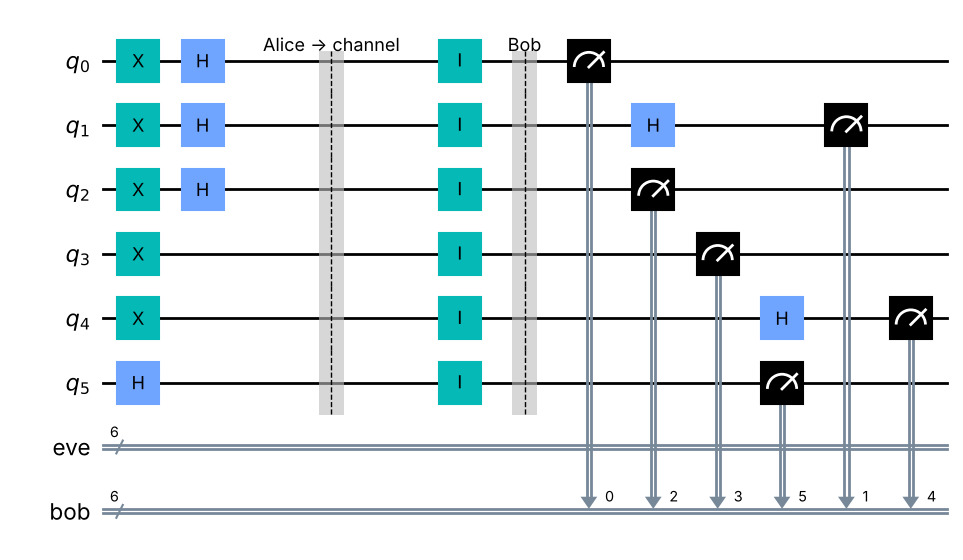

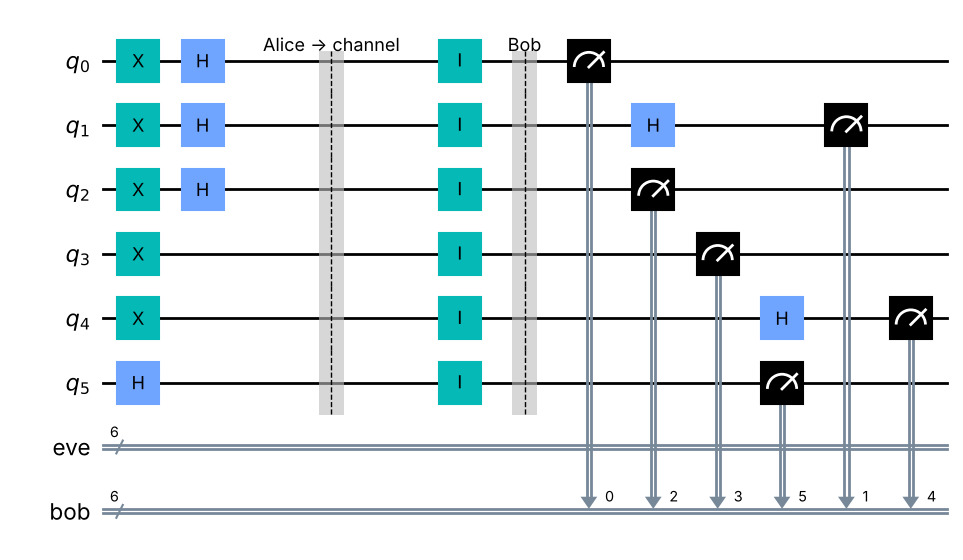

In [4]:
from qkdchat.quantum import demo_circuit, BASIS_SYMBOL
qc, info = demo_circuit(6, with_eve=False, seed=3)
print("Alice bits :", info['alice_bits'])
print("Alice bases:", [BASIS_SYMBOL[int(b)] for b in info['alice_bases']])
print("Bob bases  :", [BASIS_SYMBOL[int(b)] for b in info['bob_bases']])
qc.draw('mpl', fold=-1, style='clifford')

## 4. One key exchange, qubit by qubit

In [5]:
from qkdchat import BB84Protocol, Eavesdropper, ChannelNoise
proto = BB84Protocol(seed=42)
rep = proto.run(2048)
tx = proto.last_transmission

def trace(tx, k=16):
    return pd.DataFrame({
        'Alice bit': tx.alice_bits[:k], 'Alice basis': [BASIS_SYMBOL[int(b)] for b in tx.alice_bases[:k]],
        'State': [STATE_SYMBOL[(int(a), int(b))] for a, b in zip(tx.alice_bits[:k], tx.alice_bases[:k])],
        'Eve basis': [BASIS_SYMBOL[int(b)] if m else '-' for b, m in zip(tx.eve_bases[:k], tx.eve_mask[:k])],
        'Bob basis': [BASIS_SYMBOL[int(b)] for b in tx.bob_bases[:k]], 'Bob result': tx.bob_results[:k],
        'Sifted': tx.alice_bases[:k] == tx.bob_bases[:k],
        'Error': (tx.alice_bases[:k] == tx.bob_bases[:k]) & (tx.alice_bits[:k] != tx.bob_results[:k]),
    })
trace(tx)

,Alice bit,Alice basis,State,Eve basis,Bob basis,Bob result,Sifted,Error
0,1,x,|->,-,+,0,False,False
1,0,+,|0>,-,x,0,False,False
2,1,+,|1>,-,+,1,True,False
3,0,x,|+>,-,x,0,True,False
4,1,x,|->,-,x,1,True,False
5,1,x,|->,-,+,1,False,False
6,0,+,|0>,-,x,1,False,False
7,1,x,|->,-,x,1,True,False
8,1,x,|->,-,x,1,True,False
9,1,+,|1>,-,+,1,True,False


In [6]:
pd.Series(rep.to_dict()).drop(['timings', 'public_channel']).to_frame('clean channel')

,clean channel
n_raw,2048
n_sifted,1021
n_sample,255
n_reconciled,766
final_length,667
qber_estimate,0.0
qber_true,0.0
qber_used_for_pa,0.0
errors_corrected,0
residual_errors,0


## 5. Eve attacks: intercept-resend

Eve measures each qubit in a random basis and re-sends what she saw. Half the time she picks the wrong basis and disturbs the state; Bob then gets a wrong bit half of those times → **QBER = ½ × ½ = 25 %**. Rows marked `Error` below are her fingerprints.

In [7]:
proto_eve = BB84Protocol(eve=Eavesdropper(1.0), seed=42)
rep_eve = proto_eve.run(2048)
display(trace(proto_eve.last_transmission))
print(f"Estimated QBER = {rep_eve.qber_estimate:.1%}  ->  aborted: {rep_eve.aborted} ({rep_eve.abort_reason})")

,Alice bit,Alice basis,State,Eve basis,Bob basis,Bob result,Sifted,Error
0,1,x,|->,+,+,0,False,False
1,0,+,|0>,x,x,0,False,False
2,1,+,|1>,x,+,0,True,True
3,0,x,|+>,+,x,1,True,True
4,1,x,|->,+,x,0,True,True
5,1,x,|->,+,+,1,False,False
6,0,+,|0>,x,x,1,False,False
7,1,x,|->,+,x,0,True,True
8,1,x,|->,x,x,1,True,False
9,1,+,|1>,x,+,1,True,False


Estimated QBER = 25.9%  ->  aborted: True (QBER 25.9% exceeds 11% - eavesdropper suspected)


## 6. Post-processing on the classical channel

* **Sifting** keeps only positions where the bases matched (≈50 %).
* **Parameter estimation** reveals a random 25 % of the sifted bits and discards them.
* **Cascade** fixes remaining errors by comparing block parities; each disclosed parity is one bit leaked to Eve.
* **Privacy amplification** compresses the key with a random Toeplitz matrix to `n[1 − h(Q)] − leak` bits.

Below, a noisy (but honest) channel: errors exist, Cascade removes them, and both parties end up with *identical* keys.

In [8]:
rep_noisy = BB84Protocol(noise=ChannelNoise(channel_flip=0.08), seed=7).run(4096)
cols = ['n_raw','n_sifted','n_sample','n_reconciled','qber_estimate','qber_true','errors_corrected','leaked_ec','residual_errors','verified','final_length','key_rate','keys_match']
pd.DataFrame([{k: rep.to_dict()[k] for k in cols}, {k: rep_noisy.to_dict()[k] for k in cols}], index=['clean', 'noisy p=0.08']).T

,clean,noisy p=0.08
n_raw,2048,4096
n_sifted,1021,2132
n_sample,255,533
n_reconciled,766,1599
qber_estimate,0.0,0.050657
qber_true,0.0,0.046904
errors_corrected,0,75
leaked_ec,19,520
residual_errors,0,0
verified,True,True


In [9]:
print("What Eve sees on the public channel:")
pd.DataFrame(BB84Protocol(noise=ChannelNoise(channel_flip=0.08), seed=7).run(4096).public_channel).T

What Eve sees on the public channel:


,messages,bits
bases,2,8192
sample_positions,1,0
sample_values,2,1066
cascade_parity,520,520
cascade_permutation_seed,3,0
verify_tag,1,64
toeplitz_seed,1,0


## 7. Using the key: encrypted chat

In [10]:
from qkdchat import SecureLink
link = SecureLink(mode='otp', seed=1)
for sender, text in [('Alice', 'Hi Bob! This is protected by BB84.'), ('Bob', 'Got it - one-time pad, unbreakable.')]:
    d = link.send(sender, text)
    print(f"{d.sender} -> {d.receiver}\n  wire : {d.ciphertext.hex(64)}\n  reads: {d.decrypted}\n  key bits used: {d.key_bits_used}\n")
link.stats()

Alice -> Bob
  wire : 62f333895213efc6e5336770c173b70ef07e8f23c9415dd0d3b180abdcb4c27b...
  reads: Hi Bob! This is protected by BB84.
  key bits used: 272

Bob -> Alice
  wire : cab60140c9bc2034a02eccda59410033789b443b8e91010d4b6878c56e92070d...
  reads: Got it - one-time pad, unbreakable.
  key bits used: 280



{'exchanges': 1,
 'aborted': 0,
 'qubits_sent': 2048,
 'secret_bits_generated': 665,
 'mean_qber': 0.0,
 'pool_alice': 113,
 'pool_bob': 113,
 'bits_consumed': 552}

In [11]:
link.set_eve(1.0)
try:
    link.send('Alice', 'x' * 400)   # needs a fresh key -> BB84 runs under attack
except Exception as e:
    print(type(e).__name__, '-', e)

EavesdropperDetected - QBER 23.6% exceeds 11% - eavesdropper suspected


## 8. Realistic hardware noise (optional, ~10 s)

`hardware='fake_torino'` replaces the idealised noise with a calibration snapshot of IBM's 133-qubit *Torino* processor (T1/T2, gate and readout errors), so the protocol runs as it would on that device - without needing an IBM account.

In [12]:
rep_hw = BB84Protocol(hardware='fake_torino', seed=3).run(2048)
print(f"backend={rep_hw.backend}  QBER={rep_hw.qber_true:.2%}  final key={rep_hw.final_length} bits  rate={rep_hw.key_rate:.3f}")

backend=aer_mps+fake_torino_noise  QBER=6.17%  final key=96 bits  rate=0.047
